In [1]:
#%pip install tensorflow

In [2]:
from tensorflow.keras.datasets import mnist

(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Train:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (60000, 28, 28) (60000,)
Test: (10000, 28, 28) (10000,)


In [3]:
#Cambiamos forma que acepte MLCP y de paso aplanamos/normalizamos las imagenes para consumir menos RAM.
X_train = X_train.reshape(len(X_train), -1)
X_test = X_test.reshape(len(X_test), -1)

X_train = X_train / 255.0
X_test = X_test / 255.0

In [4]:
X_train.shape

(60000, 784)

In [5]:
CANDIDATES = [
    ("MLP 64",            (64,)),
    ("MLP 128",           (128,)),
    ("MLP 256",           (256,)),
    ("MLP 512",           (512,)),
    ("MLP 256-128",       (256, 128)),
    ("MLP 512-256",       (512, 256)),
    ("MLP 256-128-64",    (256, 128, 64)),
]

In [6]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
import time
import numpy as np

#Mide parametros y tamaño de la red
def weights_kb(mlp):
    arrays = list(mlp.coefs_) + list(mlp.intercepts_)
    n = sum(a.size for a in arrays)
    kb = sum(a.nbytes for a in arrays) / 1024
    return n, kb

#Mide latencia predicciones
def latency(predict, X, n_single=500):
    idx = np.random.default_rng(0).integers(0, len(X), n_single)
    ts = []
    for i in idx:
        t0 = time.perf_counter()
        predict(X[i:i+1])
        ts.append(time.perf_counter() - t0)
    return np.median(ts) * 1e3 #ms/imagen

ALPHA=0.00001
for name, layers in CANDIDATES:
    model = MLPClassifier(hidden_layer_sizes=layers, activation="relu", solver="adam", alpha=ALPHA,
                          batch_size=256, learning_rate_init=0.001, max_iter=50,
                          early_stopping=True, validation_fraction=0.1, n_iter_no_change=5,
                          random_state=42)
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_time = time.perf_counter() - t0

    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    params, kb = weights_kb(model)

    #Prueba de estres
    lat = latency(model.predict, X_test)

    print(f"{name:12s} acc={acc:.4f}  fit={fit_time:5.1f}s params={params} size={kb:.4f} KiB latency={lat:.3f}ms")


MLP 64       acc=0.9725  fit= 23.2s params=50890 size=397.5781 KiB latency=0.042ms
MLP 128      acc=0.9754  fit= 11.6s params=101770 size=795.0781 KiB latency=0.050ms
MLP 256      acc=0.9803  fit= 21.9s params=203530 size=1590.0781 KiB latency=0.064ms
MLP 512      acc=0.9814  fit= 52.9s params=407050 size=3180.0781 KiB latency=0.090ms
MLP 256-128  acc=0.9804  fit= 24.8s params=235146 size=1837.0781 KiB latency=0.069ms
MLP 512-256  acc=0.9832  fit= 69.3s params=535818 size=4186.0781 KiB latency=0.108ms
MLP 256-128-64 acc=0.9798  fit= 26.3s params=242762 size=1896.5781 KiB latency=0.072ms


In [7]:
from sklearn.metrics import classification_report

NAME="MLP 256-128" #Muy ligero en training y tamaño, acc es estable
LAYERS=(256, 128)
model = MLPClassifier(hidden_layer_sizes=LAYERS, activation="relu", solver="adam", alpha=ALPHA,
                          batch_size=256, learning_rate_init=0.001, max_iter=50,
                          early_stopping=True, validation_fraction=0.1, n_iter_no_change=5,
                          random_state=42)

t0 = time.perf_counter()
model.fit(X_train, y_train)
fit_time = time.perf_counter() - t0

y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
classification_report(y_test, y_pred)

params, kb = weights_kb(model)

#Prueba de estres
latency = latency(model.predict, X_test)

print(NAME)
print("Accuracy: ", acc)
print(classification_report(y_test, y_pred))
print(f"Train time  :{fit_time:.4f}s")
print("Params: ", params)
print(f"Size  {kb:.4f} KiB")
print(f"Latency {lat:.3f}ms")


MLP 256-128
Accuracy:  0.9804
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.97      0.98      1032
           3       0.98      0.98      0.98      1010
           4       0.98      0.98      0.98       982
           5       0.98      0.98      0.98       892
           6       0.98      0.98      0.98       958
           7       0.98      0.98      0.98      1028
           8       0.98      0.97      0.98       974
           9       0.97      0.97      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000

Train time  :27.5971s
Params:  235146
Size  1837.0781 KiB
Latency 0.072ms


# MINST-C

In [8]:
import os
import numpy as np
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

ruta_mnist_c = "./mnist_c"

corruptions = [d for d in os.listdir(ruta_mnist_c) if os.path.isdir(os.path.join(ruta_mnist_c, d))]

results = {}
for corruption in corruptions:
    route = os.path.join(ruta_mnist_c, corruption)
    
    try:
        #Carga imagenes y etiequetas
        X_test_c = np.load(os.path.join(route, 'test_images.npy'))
        y_test_c = np.load(os.path.join(route, 'test_labels.npy'))
        
        #Preprocesamiento
        X_test_c_flat = X_test_c.reshape(X_test_c.shape[0], -1) 
        X_test_c_norm = X_test_c_flat / 255.0 
        
        #Predicciones
        y_pred = model.predict(X_test_c_norm)
        acc = accuracy_score(y_test_c, y_pred)
        
        results[corruption] = acc
        print(f"Corrupcion: {corruption:15} | Accuracy: {acc:.4f}")
        
    except FileNotFoundError:
        print(f"{corruption}\nArchivos no encontrados")

acc_average = np.mean(list(results.values()))
print(f"Accuracy avg MNIST-C: {acc_average:.4f}")

Corrupcion: rotate          | Accuracy: 0.8512
Corrupcion: glass_blur      | Accuracy: 0.9485
Corrupcion: impulse_noise   | Accuracy: 0.7535
Corrupcion: scale           | Accuracy: 0.6016
Corrupcion: identity        | Accuracy: 0.9804
Corrupcion: translate       | Accuracy: 0.3069
Corrupcion: shot_noise      | Accuracy: 0.9686
Corrupcion: motion_blur     | Accuracy: 0.8015
Corrupcion: zigzag          | Accuracy: 0.6814
Corrupcion: brightness      | Accuracy: 0.2314
Corrupcion: canny_edges     | Accuracy: 0.6554
Corrupcion: fog             | Accuracy: 0.1636
Corrupcion: shear           | Accuracy: 0.9285
Corrupcion: dotted_line     | Accuracy: 0.9170
Corrupcion: spatter         | Accuracy: 0.9332
Corrupcion: stripe          | Accuracy: 0.2036
Accuracy avg MNIST-C: 0.6829


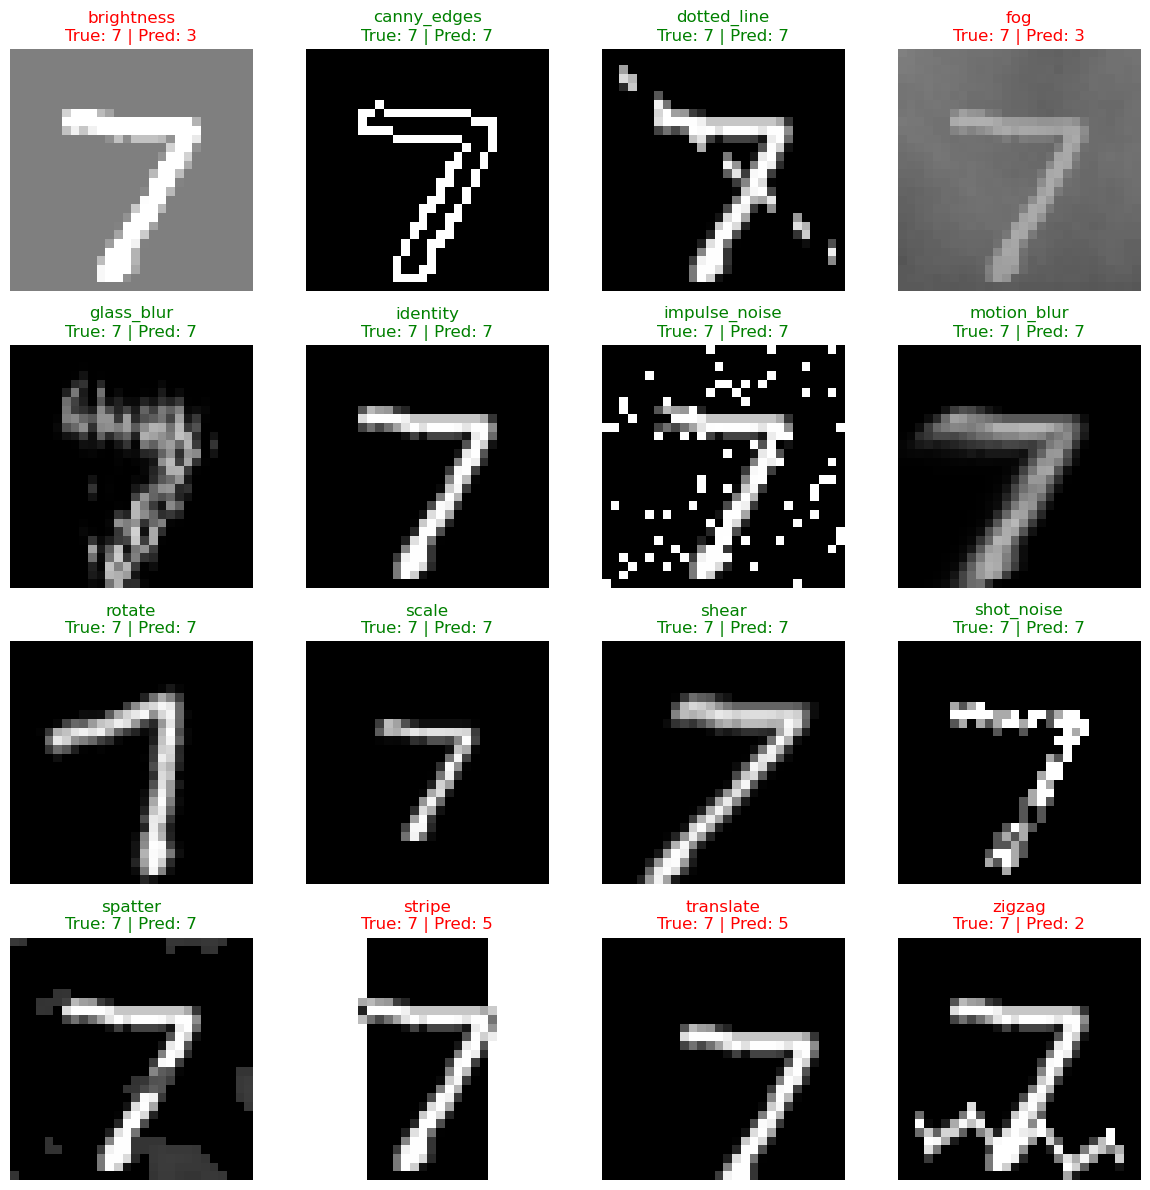

In [9]:
import os
import numpy as np
import matplotlib.pyplot as plt

ruta_mnist_c = "./mnist_c" 
corruptions = [d for d in os.listdir(ruta_mnist_c) if os.path.isdir(os.path.join(ruta_mnist_c, d))]
corruptions.sort() 
minst_index = 0 #Prueba con otro indice

fig, axes = plt.subplots(4, 4, figsize=(12, 12))
axes = axes.flatten()

for i, corruption in enumerate(corruptions):
    route = os.path.join(ruta_mnist_c, corruption)
    
    try:
        X_test_c = np.load(os.path.join(route, 'test_images.npy'))
        y_test_c = np.load(os.path.join(route, 'test_labels.npy'))
        
        #Imagen a probar
        image = X_test_c[minst_index]
        label = y_test_c[minst_index]
        
        image_norm = image.reshape(1, -1) / 255.0
        y_pred = model.predict(image_norm)[0]
        
        #Grafica
        ax = axes[i]
        ax.imshow(image, cmap='gray', vmin=0, vmax=255) 
        
        color = 'green' if y_pred == label else 'red'
        ax.set_title(f"{corruption}\nTrue: {label} | Pred: {y_pred}", color=color)
        ax.axis('off')
        
    except FileNotFoundError:
        print(f"{corruption}\nArchivos no encontrados")

plt.tight_layout()
plt.show()

### Al final MLCP logra detectar patrones del digito pero cuando son alteraciones en los pixeles como el brillo o zigzag sufren a eso contado que tenemos que aplanar la imagen para que funcione, perdiendo informacion.